# Any-Precision — SVHN / CNN-8

Two presentation figures from the completed Any-Precision reference run:

1. **Test accuracy at epoch 100:** precision on the x-axis, accuracy on the y-axis, with isolated points and percentage labels.
2. **Shared model storage:** one FP32 source and all five precision-specific BatchNorm configurations.

All data required for the figures are embedded in this notebook. **Run All** recreates the figures and exports PNG (300 dpi) and SVG files to `figures/`. The only third-party dependency is Matplotlib; no training, dataset download or checkpoint loading is required.

The figures have no explanatory footer. The details and source records are kept here in the notebook. Change the plotting settings in Section 2 to adjust the appearance.


## 1. Verified experiment settings

| Setting | Value |
|:--|:--|
| Dataset | SVHN, official training split only; **no extra set** |
| Samples | 73,257 training; 26,032 test; no separate validation split |
| Model | CNN-8 (`models.svhn_quan.svhnq`, `expand=2`), 10 classes |
| Shared training modes | W1/A1, W2/A2, W4/A4, W8/A8, W32/A32 |
| Training | 100 epochs, fresh initialization |
| Optimizer | Adam |
| Initial learning rate | 0.001 |
| Learning-rate milestones | After epochs 50, 75 and 90 |
| Learning-rate decay factor | 0.1 at each milestone |
| Batch size | 128 |
| Weight decay | 0 |
| Distillation | Recursive knowledge distillation |
| Seed | 20261009; one run |
| Preprocessing | Resize to 40 × 40 with bilinear interpolation and antialiasing; normalize RGB channels with mean 0.5 and standard deviation 0.5 |
| Data augmentation | None beyond the deterministic preprocessing above |
| Data loading | Training shuffled; test not shuffled; last partial batch retained |
| Optimization schedule | Five precision passes per minibatch and one optimizer update; 57,300 updates in total |

The learning rates used are **1e-3 for epochs 1–50**, **1e-4 for 51–75**, **1e-5 for 76–90**, and **1e-6 for 91–100**.

These are the final-epoch results of run `20261016_165710_766662_run`. The separately selected best W32/A32 checkpoint is at epoch 54; it is not used in these figures. The original implementation performs quantization-aware training with FP32 source parameters. W/A labels describe the selected quantization modes; the first convolution and final classifier remain FP32. This is the train-only experiment, not an exact reproduction of the paper's train-plus-extra protocol.


In [1]:
import csv
import io
import json
import math
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator


In [2]:
DATA = json.loads(r'''
{
  "schema": "anyprecision-svhn-cnn8-midterm-v1",
  "run_id": "20261016_165710_766662_run",
  "dataset": "SVHN",
  "model_display_name": "CNN-8",
  "model_factory": "models.svhn_quan.svhnq",
  "expand": 2,
  "training": {
    "epochs": 100,
    "optimizer": "Adam",
    "initial_learning_rate": 0.001,
    "lr_milestones": [
      50,
      75,
      90
    ],
    "lr_decay_factor": 0.1,
    "batch_size": 128,
    "weight_decay": 0.0,
    "seed": 20261009,
    "distillation": "Recursive knowledge distillation",
    "precision_bits": [
      1,
      2,
      4,
      8,
      32
    ],
    "train_samples": 73257,
    "test_samples": 26032,
    "validation_samples": 0,
    "train_split": "train",
    "extra_used": false,
    "initialization": "Fresh initialization",
    "preprocessing": "Resize to 40 x 40 (bilinear, antialias=True); ToTensor; normalize each RGB channel with mean 0.5 and standard deviation 0.5.",
    "augmentation": "None beyond the deterministic preprocessing above.",
    "train_shuffle": true,
    "test_shuffle": false,
    "drop_last": false,
    "optimizer_steps": 57300
  },
  "accuracy": [
    {
      "precision": "W1/A1",
      "bits": 1,
      "epoch": 100,
      "accuracy_percent": 86.3091579547453,
      "correct": 22468,
      "test_samples": 26032
    },
    {
      "precision": "W2/A2",
      "bits": 2,
      "epoch": 100,
      "accuracy_percent": 93.66164720344192,
      "correct": 24382,
      "test_samples": 26032
    },
    {
      "precision": "W4/A4",
      "bits": 4,
      "epoch": 100,
      "accuracy_percent": 94.85248924400737,
      "correct": 24692,
      "test_samples": 26032
    },
    {
      "precision": "W8/A8",
      "bits": 8,
      "epoch": 100,
      "accuracy_percent": 94.92163491087892,
      "correct": 24710,
      "test_samples": 26032
    },
    {
      "precision": "W32/A32",
      "bits": 32,
      "epoch": 100,
      "accuracy_percent": 94.7871849983839,
      "correct": 24675,
      "test_samples": 26032
    }
  ],
  "storage": {
    "method": "Analytical persistent tensor payload from the verified architecture; cross-checked against the earlier tensor metadata audit.",
    "shared_layers": [
      {
        "name": "layers.0",
        "kind": "Conv2d",
        "weight_shape": [
          12,
          3,
          5,
          5
        ],
        "weight_count": 900,
        "bias_count": 12,
        "parameter_count": 912,
        "parameter_dtype": "float32",
        "parameter_bytes": 3648,
        "forward_weight_quantization": false
      },
      {
        "name": "layers.3",
        "kind": "Conv2d",
        "weight_shape": [
          16,
          12,
          3,
          3
        ],
        "weight_count": 1728,
        "bias_count": 0,
        "parameter_count": 1728,
        "parameter_dtype": "float32",
        "parameter_bytes": 6912,
        "forward_weight_quantization": true
      },
      {
        "name": "layers.6",
        "kind": "Conv2d",
        "weight_shape": [
          16,
          16,
          3,
          3
        ],
        "weight_count": 2304,
        "bias_count": 0,
        "parameter_count": 2304,
        "parameter_dtype": "float32",
        "parameter_bytes": 9216,
        "forward_weight_quantization": true
      },
      {
        "name": "layers.10",
        "kind": "Conv2d",
        "weight_shape": [
          32,
          16,
          3,
          3
        ],
        "weight_count": 4608,
        "bias_count": 0,
        "parameter_count": 4608,
        "parameter_dtype": "float32",
        "parameter_bytes": 18432,
        "forward_weight_quantization": true
      },
      {
        "name": "layers.13",
        "kind": "Conv2d",
        "weight_shape": [
          32,
          32,
          3,
          3
        ],
        "weight_count": 9216,
        "bias_count": 0,
        "parameter_count": 9216,
        "parameter_dtype": "float32",
        "parameter_bytes": 36864,
        "forward_weight_quantization": true
      },
      {
        "name": "layers.16",
        "kind": "Conv2d",
        "weight_shape": [
          32,
          32,
          3,
          3
        ],
        "weight_count": 9216,
        "bias_count": 0,
        "parameter_count": 9216,
        "parameter_dtype": "float32",
        "parameter_bytes": 36864,
        "forward_weight_quantization": true
      },
      {
        "name": "layers.20",
        "kind": "Conv2d",
        "weight_shape": [
          128,
          32,
          5,
          5
        ],
        "weight_count": 102400,
        "bias_count": 0,
        "parameter_count": 102400,
        "parameter_dtype": "float32",
        "parameter_bytes": 409600,
        "forward_weight_quantization": true
      },
      {
        "name": "fc",
        "kind": "Linear",
        "weight_shape": [
          10,
          128
        ],
        "weight_count": 1280,
        "bias_count": 10,
        "parameter_count": 1290,
        "parameter_dtype": "float32",
        "parameter_bytes": 5160,
        "forward_weight_quantization": false
      }
    ],
    "bn_features": [
      16,
      16,
      32,
      32,
      32
    ],
    "bn_banks": 5,
    "expected_total_bytes": 537136,
    "expected_parameter_count": 132954,
    "float32_bytes": 4,
    "int64_bytes": 8,
    "exclusions": [
      "Optimizer state",
      "Gradients",
      "Activations and temporary quantized tensors",
      "Serialization overhead and Python objects"
    ]
  },
  "provenance": {
    "source_archive": "svhn_trainonly_reference100_feedbackanalyse_v1.zip",
    "source_archive_library_id": "libfile_0a37eb1624908191854dd6da28727245",
    "source_member_sha256": {
      "bronnen/reference100/run_report.json": "69a96f7059b7cc0a8ee01c7c4982b1ea4f75c8419e04f234d3b4ddad0ea28e5e",
      "bronnen/reference100/epoch_metrics.csv": "64c1b4765bcdb53685f3fec316f926efc4bf1dca469cd003cb21066e8793591a",
      "bronnen/reference100/learning_rate_schedule.csv": "2d4b15db524f3fd0d8213b201f95987b6a8d0b5b3a691c6e50a346a900429b4c"
    },
    "original_code_archive": "Any-Precision-DNNs-master.zip",
    "original_code_archive_sha256": "7e36c5f039a78e3174421de7ff097066f95dde2837ea02f11913f3be0ba7f73c",
    "model_source_sha256": {
      "models/svhn_quan.py": "c891da23c7d2934cd65e3c596c3e47b47de8987385bc8d06eab22de7d2d02e74",
      "models/quan_ops.py": "86fc8f68e3060f98913cb7f1b33f698f43bf8d2b6d85a3ad92c30f6e19a70f71",
      "train.py": "318ef0c73b80634e9a4de0cf7dbf7caff2c0761abfa8d48c78b08a9a8d266b5b"
    },
    "epoch100_checkpoint_sha256": "8eeba15f736f438673317f91e8f297769adde7ac8bc60bcbd79687fd7abc7a32",
    "checkpoint_bytes_loaded_for_this_notebook": false,
    "storage_cross_check": "MX_onderzoeksoverzicht_meeting_20261029.ipynb, costs.metadata.all_model_state_bytes",
    "storage_cross_check_bytes": 537136,
    "reported_metric_field": "top1_percent",
    "single_run": true
  }
}
''')


## 2. Plot settings

The default accuracy view retains the original full scale. Only the bars are replaced by points. Precision positions are equally spaced categories; no connecting line is drawn.

For an optional zoom, change `ACCURACY_YLIM` to `(84, 100)` and `ACCURACY_YTICKS` to `list(range(84, 101, 2))`. This only changes the view, not the data. All figure text is English.


In [3]:
FIGURE_SIZE = (13.6, 7.2)
EXPORT_DPI = 300
EXPORT_DIR = Path('figures')

ACCURACY_YLIM = (0, 105)   # Small headroom above 100 for labels.
ACCURACY_YTICKS = [0, 20, 40, 60, 80, 100]
POINT_SIZE = 170
LABEL_DECIMALS = 3

NAVY = '#19384B'
MUTED = '#526C7E'
GRID = '#DDE5EB'
SPINE = '#BCCAD4'
PRECISION_COLORS = ['#9BAEBE', '#7195B0', '#477C9F', '#25658A', '#19384B']
SHARED_COLOR = '#25658A'
BN_COLOR = '#73B5AC'

mpl.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 13,
    'text.color': NAVY,
    'axes.labelcolor': NAVY,
    'xtick.color': NAVY,
    'ytick.color': NAVY,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'svg.fonttype': 'none',
    'savefig.facecolor': 'white',
})

def add_heading(fig, training=False):
    fig.text(0.055, 0.945, 'Any-Precision', fontsize=25, weight='bold', va='top')
    fig.text(0.055, 0.875, 'Dataset: SVHN  |  Model: CNN-8', fontsize=17, va='top')
    if training:
        t = DATA['training']
        fig.text(
            0.055, 0.813,
            f"Epochs: {t['epochs']}  |  {t['optimizer']}  |  Initial LR: {t['initial_learning_rate']:g}  |  Batch size: {t['batch_size']}",
            fontsize=13, color=MUTED, va='top',
        )
        milestones = ', '.join(map(str, t['lr_milestones']))
        fig.text(
            0.055, 0.770,
            f"LR milestones: {milestones}  |  LR decay factor: {t['lr_decay_factor']:g}",
            fontsize=13, color=MUTED, va='top',
        )

def style_axes(ax):
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('bottom', 'left'):
        ax.spines[side].set_color(SPINE)
        ax.spines[side].set_linewidth(0.9)
    ax.tick_params(labelsize=13, length=4, width=0.8)


## 3. Figure 1 — test accuracy

The five values are taken directly from the logged `top1_percent` field at **epoch 100**. Labels use three decimal places and an English decimal point. No averaging or best-checkpoint selection is applied. There are no error bars because these measurements come from one run.


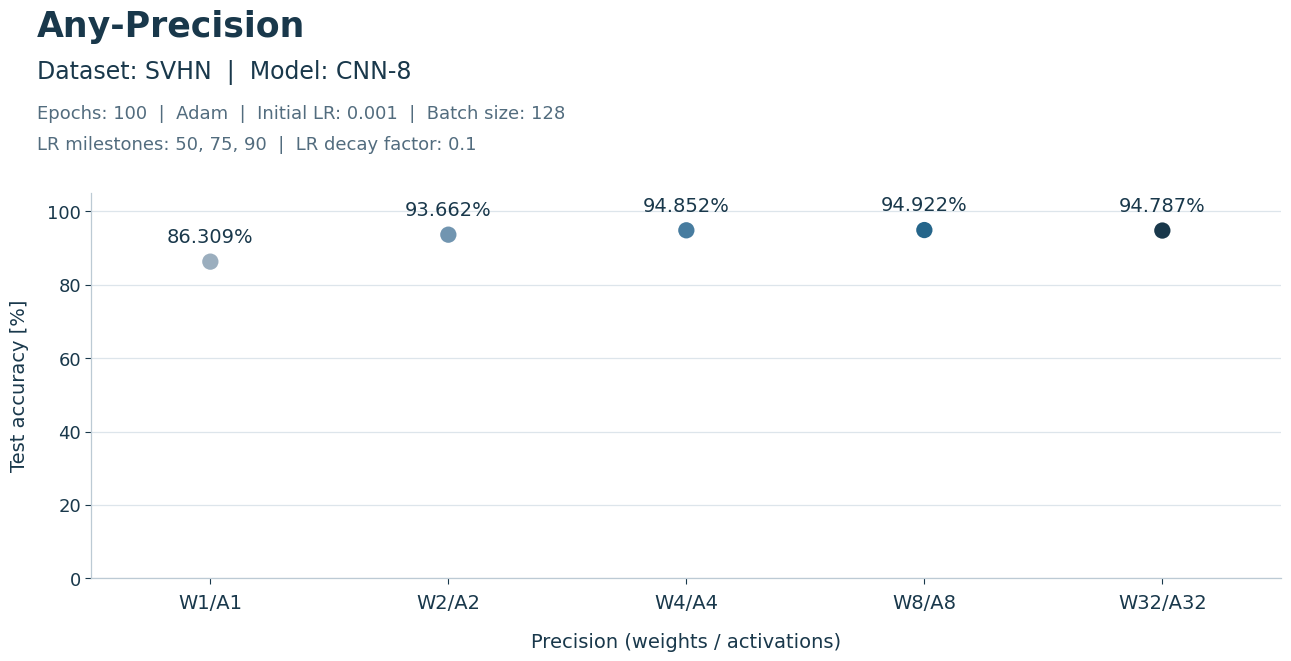

In [4]:
accuracy_rows = DATA['accuracy']
assert [r['bits'] for r in accuracy_rows] == [1, 2, 4, 8, 32]
assert all(r['epoch'] == 100 and r['test_samples'] == 26032 for r in accuracy_rows)
for row in accuracy_rows:
    count_accuracy = 100 * row['correct'] / row['test_samples']
    assert abs(count_accuracy - row['accuracy_percent']) < 1e-6

positions = list(range(len(accuracy_rows)))
labels = [r['precision'] for r in accuracy_rows]
accuracies = [r['accuracy_percent'] for r in accuracy_rows]

fig_accuracy = plt.figure(figsize=FIGURE_SIZE)
add_heading(fig_accuracy, training=True)
ax_accuracy = fig_accuracy.add_axes([0.095, 0.155, 0.875, 0.535])
style_axes(ax_accuracy)
ax_accuracy.yaxis.grid(True, color=GRID, linewidth=0.9)
ax_accuracy.scatter(
    positions, accuracies, s=POINT_SIZE, c=PRECISION_COLORS,
    edgecolors='white', linewidths=1.3, zorder=3,
)
for x, accuracy in zip(positions, accuracies):
    ax_accuracy.annotate(
        f'{accuracy:.{LABEL_DECIMALS}f}%', (x, accuracy),
        xytext=(0, 11), textcoords='offset points',
        ha='center', va='bottom', fontsize=14, color=NAVY,
    )
ax_accuracy.set_xticks(positions, labels)
ax_accuracy.tick_params(axis='x', labelsize=14, pad=7)
ax_accuracy.set_xlim(-0.5, len(positions) - 0.5)
ax_accuracy.set_ylim(*ACCURACY_YLIM)
ax_accuracy.yaxis.set_major_locator(FixedLocator(ACCURACY_YTICKS))
ax_accuracy.set_xlabel('Precision (weights / activations)', fontsize=14, labelpad=14)
ax_accuracy.set_ylabel('Test accuracy [%]', fontsize=14, labelpad=13)
plt.show()


### Values shown

| Precision | Test accuracy | Correct predictions |
|:--|--:|--:|
| W1/A1 | 86.309% | 22,468 / 26,032 |
| W2/A2 | 93.662% | 24,382 / 26,032 |
| W4/A4 | 94.852% | 24,692 / 26,032 |
| W8/A8 | 94.922% | 24,710 / 26,032 |
| W32/A32 | 94.787% | 24,675 / 26,032 |


## 4. Figure 2 — shared model storage

**Metric:** the logical byte size of all persistent model tensors required by this implementation to support the five modes together. The shared convolution and linear parameters are stored once in FP32. Each precision has its own BatchNorm affine parameters and running statistics; all five banks and their int64 counters are included.

This is an analytical size computed from the verified architecture and checked against the earlier tensor metadata audit. It is not a measured checkpoint file size or a runtime peak-memory measurement. Optimizer state, gradients, activations, temporary quantized tensors and serialization overhead are outside this metric.

For `k` precision-specific BatchNorm banks:

\[
S(k) = 526{,}696 + 2{,}088k\quad\text{bytes}.
\]

Here `k=5`, giving **537,136 bytes = 524.546875 KiB** (1 KiB = 1,024 bytes). The total does not change when selecting a different active precision while retaining all five modes. No separate packed low-bit model copies are added.


In [5]:
storage = DATA['storage']
shared_parameter_count = sum(
    math.prod(layer['weight_shape']) + layer['bias_count']
    for layer in storage['shared_layers']
)
bn_channels = sum(storage['bn_features'])
banks = storage['bn_banks']
bn_sites = len(storage['bn_features'])

shared_bytes = shared_parameter_count * storage['float32_bytes']
bn_parameter_count = 2 * bn_channels * banks
bn_parameter_bytes = bn_parameter_count * storage['float32_bytes']
bn_running_bytes = 2 * bn_channels * banks * storage['float32_bytes']
bn_counter_bytes = bn_sites * banks * storage['int64_bytes']
bn_bytes = bn_parameter_bytes + bn_running_bytes + bn_counter_bytes
total_bytes = shared_bytes + bn_bytes

assert shared_parameter_count + bn_parameter_count == storage['expected_parameter_count']
assert total_bytes == storage['expected_total_bytes'] == 537136
assert total_bytes == DATA['provenance']['storage_cross_check_bytes']

storage_components = [
    {'component': 'Shared FP32 convolution and linear parameters', 'bytes': shared_bytes},
    {'component': 'BatchNorm affine parameters, all five banks', 'bytes': bn_parameter_bytes},
    {'component': 'BatchNorm running statistics, all five banks', 'bytes': bn_running_bytes},
    {'component': 'BatchNorm counters, all five banks', 'bytes': bn_counter_bytes},
]
for component in storage_components:
    print(f"{component['component']}: {component['bytes']:,} bytes ({component['bytes'] / 1024:.6f} KiB)")
print(f'TOTAL: {total_bytes:,} bytes = {total_bytes / 1024:.6f} KiB')


Shared FP32 convolution and linear parameters: 526,696 bytes (514.351562 KiB)
BatchNorm affine parameters, all five banks: 5,120 bytes (5.000000 KiB)
BatchNorm running statistics, all five banks: 5,120 bytes (5.000000 KiB)
BatchNorm counters, all five banks: 200 bytes (0.195312 KiB)
TOTAL: 537,136 bytes = 524.546875 KiB


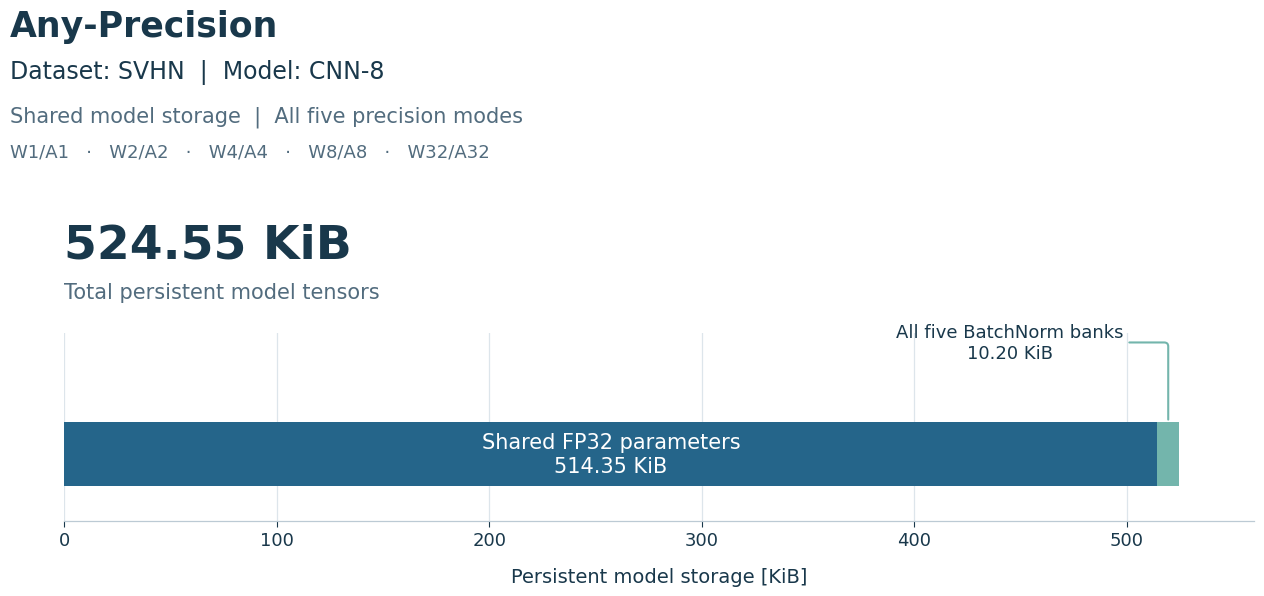

In [6]:
shared_kib = shared_bytes / 1024
bn_kib = bn_bytes / 1024
total_kib = total_bytes / 1024

fig_storage = plt.figure(figsize=FIGURE_SIZE)
add_heading(fig_storage)
fig_storage.text(
    0.055, 0.811, 'Shared model storage  |  All five precision modes',
    fontsize=15, color=MUTED, va='top',
)
fig_storage.text(
    0.055, 0.760, 'W1/A1   ·   W2/A2   ·   W4/A4   ·   W8/A8   ·   W32/A32',
    fontsize=13, color=MUTED, va='top',
)
fig_storage.text(0.095, 0.649, f'{total_kib:.2f} KiB', fontsize=34, weight='bold', va='top')
fig_storage.text(0.095, 0.566, 'Total persistent model tensors', fontsize=15, color=MUTED, va='top')

ax_storage = fig_storage.add_axes([0.095, 0.235, 0.875, 0.26])
style_axes(ax_storage)
ax_storage.spines['left'].set_visible(False)
ax_storage.xaxis.grid(True, color=GRID, linewidth=0.9)
ax_storage.barh(0, shared_kib, height=0.56, color=SHARED_COLOR, zorder=3)
ax_storage.barh(0, bn_kib, left=shared_kib, height=0.56, color=BN_COLOR, zorder=3)
ax_storage.text(
    shared_kib / 2, 0, f'Shared FP32 parameters\n{shared_kib:.2f} KiB',
    color='white', fontsize=15, ha='center', va='center',
)
ax_storage.annotate(
    f'All five BatchNorm banks\n{bn_kib:.2f} KiB',
    xy=(shared_kib + bn_kib / 2, 0.28), xytext=(445, 0.81),
    ha='center', va='bottom', fontsize=13, color=NAVY,
    arrowprops={'arrowstyle': '-', 'color': BN_COLOR, 'linewidth': 1.5,
                'connectionstyle': 'angle,angleA=0,angleB=90,rad=4'},
)
ax_storage.set_xlim(0, 560)
ax_storage.set_ylim(-0.58, 1.06)
ax_storage.set_yticks([])
ax_storage.set_xticks([0, 100, 200, 300, 400, 500])
ax_storage.set_xlabel('Persistent model storage [KiB]', fontsize=14, labelpad=13)
plt.show()


## 5. Export

The PNG files use 300 dpi and the SVG files retain editable text and vector shapes. Re-running this cell updates only these named exports in `figures/`. The JSON and CSV files preserve the unrounded values used in the figures.


In [7]:
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
figures = {
    'anyprecision_accuracy_epoch100': fig_accuracy,
    'anyprecision_shared_model_storage': fig_storage,
}
for name, figure in figures.items():
    for extension in ('png', 'svg'):
        path = EXPORT_DIR / f'{name}.{extension}'
        buffer = io.BytesIO()
        figure.savefig(buffer, format=extension, dpi=EXPORT_DPI, facecolor='white')
        path.write_bytes(buffer.getvalue())
        print(f'Saved: {path.as_posix()}')

with (EXPORT_DIR / 'accuracy_epoch100.csv').open('w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(accuracy_rows[0]))
    writer.writeheader()
    writer.writerows(accuracy_rows)

with (EXPORT_DIR / 'model_storage.csv').open('w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=['component', 'bytes'])
    writer.writeheader()
    writer.writerows(storage_components + [{'component': 'Total', 'bytes': total_bytes}])

(EXPORT_DIR / 'figure_data.json').write_text(json.dumps(DATA, indent=2) + '\n', encoding='utf-8')
print('Saved: accuracy_epoch100.csv, model_storage.csv and figure_data.json')


Saved: figures/anyprecision_accuracy_epoch100.png
Saved: figures/anyprecision_accuracy_epoch100.svg
Saved: figures/anyprecision_shared_model_storage.png
Saved: figures/anyprecision_shared_model_storage.svg
Saved: accuracy_epoch100.csv, model_storage.csv and figure_data.json


## 6. Sources and interpretation

- **Experiment records:** `svhn_trainonly_reference100_feedbackanalyse_v1.zip`, members `bronnen/reference100/run_report.json`, `epoch_metrics.csv` and `learning_rate_schedule.csv`. The original byte-for-byte members are included in the accompanying package under `provenance/reference100/`.
- **Storage accounting:** `models/svhn_quan.py` and `models/quan_ops.py` in the original `Any-Precision-DNNs-master.zip`, using the verified factory configuration `expand=2`. The model-source hashes match the actual run report. The result also matches `costs.metadata.all_model_state_bytes` in `MX_onderzoeksoverzicht_meeting_20261029.ipynb`.
- **Numerical integrity:** the logged `top1_percent` values are retained, including tiny floating-point differences from percentages recomputed from the integer correct-prediction counts. The difference is below 1e-6 percentage points. Only the visible labels are rounded.
- **Model scope:** one shared FP32 source supports the five precision modes; this notebook does not assume that an 8-bit source can reconstruct the W32/A32 mode.
- **Interpretation:** test accuracy and persistent model storage are different metrics. Neither figure measures DRAM bandwidth, energy, inference latency or the additional state required for continual learning.

Source-member checksums and the reported epoch-100 checkpoint checksum are embedded in `DATA['provenance']`. The checkpoint itself was not loaded to build these figures. The full tensor-size accounting is included as `provenance/storage_audit.json` in the accompanying package.
